# Karst aquifer model (LuKARS): active subspace of a Bayesian data misfit

**Paper:** Mario Teixeira Parente¹, Daniel Bittner², Steven A. Mattis¹, Gabriele Chiogna²˒³, and Barbara Wohlmuth¹, "Bayesian Calibration and Sensitivity Analysis for a Karst Aquifer Model Using Active Subspaces", *Water Resources Research* 55(8):7086–7107, 2019. [doi:10.1029/2019WR024739](https://doi.org/10.1029/2019WR024739)

¹ Chair for Numerical Mathematics, Technical University Munich, Munich, Germany
² Chair of Hydrology and River Basin Management, Technical University Munich, Munich, Germany
³ Institute of Geography, University of Innsbruck, Innsbruck, Austria

Notebook: Claude (Anthropic) for P. Constantine, 2026

## Summary

LuKARS is a lumped model of a karst spring that sums the quickflow of three soil/land-cover units (hydrotopes) and a shared baseflow store; Teixeira Parente et al. calibrated its 21 hydrotope parameters to the daily discharge of the Kerschbaum spring (Austria, 2006–2008) through the Bayesian data misfit with 5 % Gaussian noise. This notebook uses a numpy port of the authors' R code, which reproduces it to round-off, with 1000 Monte Carlo samples of the paper's normalized calibration parameters and exact gradients of the misfit. With exact (pathwise) gradients the misfit has a two-dimensional active subspace (λ₁/λ₂ = 1.85, λ₂/λ₃ = 6.73) spanned by the quickflow and recharge coefficients of hydrotopes 1 and 2, and a quartic polynomial on those two active variables predicts 5000 independent misfits with R² = 0.787; the paper's larger spectrum, with its first gap after λ₁, is largely reproduced by finite differences taken through the 6-decimal rounding of the parameters in the authors' code interface, so it is likely, though not confirmed, a gradient artifact.

## Active subspaces in brief

For a function $f(\mathbf{x})$ of $m$ inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf{C} = \int \nabla f\, \nabla f^\top \rho\, d\mathbf{x} = \mathbf{W}\Lambda\mathbf{W}^\top$. A gap after $\lambda_n$ means that, on average, $f$ changes much more along the first $n$ eigenvectors $\mathbf{W}_1$ than along the rest, so $f(\mathbf{x}) \approx g(\mathbf{W}_1^\top \mathbf{x})$ and a plot of $f$ against the active variables $\mathbf{y} = \mathbf{W}_1^\top\mathbf{x}$ (a sufficient summary plot) shows the structure. $\mathbf{C}$ is estimated from sampled gradients, and the bootstrap gives the variability of the eigenvalues and subspaces. See P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM, 2015, [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).

In [1]:
%matplotlib inline
import time
import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import lukars_model as lm

SEED = 2019
T0 = time.time()
np.set_printoptions(precision=4, suppress=False, linewidth=110)

## The model

**LuKARS** (Bittner et al., 2018; paper Appendix A). The Kerschbaum spring recharge area (2.5 km²) has three calibrated hydrotopes, Hyd 1 (13 % of the area, shallow coarse soils), Hyd 2 (56 %) and Hyd 3 (27 %, deep fine soils); a dolomite quarry (4 %) does not reach the spring and is left out. Each hydrotope $i$ is a bucket with water level $e_i$ (mm), and a linear baseflow store $e_b$ is shared. With a daily step $\Delta t = 1$ day,

$$e_{i,n+1} = \max\Big[0,\; e_{i,n} + \Big(S_n - \frac{Q_{\mathrm{sec},i,n} + Q_{\mathrm{is},i,n} + Q_{\mathrm{hyd},i,n}}{a_i}\Big)\Delta t\Big],\qquad
e_{b,n+1} = e_{b,n} + \frac{\sum_i Q_{\mathrm{is},i,n} - Q_{b,n}}{A}\,\Delta t,$$

$$Q_{\mathrm{hyd},i} = \varepsilon_i \Big(\frac{e_i - e_{\min,i}}{e_{\max,i} - e_{\min,i}}\Big)^{\alpha_i} \frac{k_{\mathrm{hyd},i}}{l_{\mathrm{hyd},i}}\, a_i,\quad
Q_{\mathrm{is},i} = k_{\mathrm{is},i}\, e_i\, a_i,\quad
Q_{\mathrm{sec},i} = k_{\mathrm{sec},i} \max(0, e_i - e_{\mathrm{sec},i})\, a_i,\quad
Q_b = k_b\, e_b\, A .$$

The switch $\varepsilon_i$ is a hysteresis: quickflow starts when $e_i$ reaches $e_{\max,i}$ and stops when $e_i$ falls below $e_{\min,i}$. Spring discharge is $Q = \sum_i Q_{\mathrm{hyd},i} + Q_b$; $Q_{\mathrm{sec}}$ leaves the catchment. The source term $S_n$ (precipitation minus interception, with degree-day snow accumulation and melt, minus Thornthwaite evapotranspiration) is computed from the daily precipitation and temperature series exactly as in the authors' R script. Fixed settings (from the script): $k_b = 0.00043$ day⁻¹, $l_{\mathrm{hyd}} = 1600, 900, 960$ m, melt factor 4 mm °C⁻¹ day⁻¹, melt threshold 0.5 °C, initial $e_b = 2900$ mm and $e_i = 0$. The run starts on 2001-01-01, and the five years to 2005 are spin-up, as in the authors' 2020 script; the paper describes only the 2006–2008 model period, so whether its runs had this spin-up is an open question (DATA.md).

**Quantity of interest.** The Bayesian data misfit (paper Eq. 20 and Sec. 4) over the 1096 days $t$ from 2006-01-01 to 2008-12-31,
$$f_d(\mathbf{x}) = \tfrac12 \sum_t \Big(\frac{d_t - G_t(\mathbf{x})}{0.05\, d_t}\Big)^2,$$
with $d_t$ the measured discharge and $G_t$ the simulated discharge (l/s). The simulated series is also stored (`discharge.npz`).

**Inputs.** The 21 physical parameters (seven per hydrotope, Table 1) must satisfy the ordering of Eq. (1) ($k_{\mathrm{hyd}}, \alpha, k_{\mathrm{is}}, k_{\mathrm{sec}}$ decrease and $e_{\min}, e_{\max}, e_{\mathrm{sec}}$ increase from Hyd 1 to Hyd 3) and $e_{\min,i} \le e_{\max,i}$. The paper therefore calibrates independent parameters (Sec. 3.5): the $k$'s on a log scale (Eq. 28); for Hyd 2 and 3, the fraction $\triangle p_{(i-1,i)} \in [0, 1]$ of the range left by the previous hydrotope (Eqs. 29–30); and $\triangle e_i = e_{\max,i} - e_{\min,i}$ in place of $e_{\max,i}$ (Eqs. 31–32). Each is scaled to $[-1, 1]$, giving $\mathbf{x} \in [-1, 1]^{21}$ (Eq. 33), and the prior is $\mathbf{x} \sim U[-1, 1]^{21}$. The physical prior is then not uniform. The table below is printed from `lukars_model.py`.

In [2]:
units = lm.UNITS
cal_lo = lm.INTERIM_LB.reshape(3, 7)
cal_hi = lm.INTERIM_UB.reshape(3, 7)
print(f"{'No.':>3}  {'physical':<9} {'units':<12} {'Table 1 range':<20} {'calibration x_j':<15} {'interval of x_j before scaling to [-1, 1]'}")
for j, (nm, cn) in enumerate(zip(lm.NAMES, lm.CAL_NAMES)):
    i, k = divmod(j, 7)
    kind = lm.KINDS[k]
    rng_txt = f"[{lm.LB[i, k]:g}, {lm.UB[i, k]:g}]"
    if i == 0 or k == 2:
        lo, hi = cal_lo[i, k], cal_hi[i, k]
        iv = f"[{lo:.4g}, {hi:.4g}]" + (" (ln)" if k in lm.LOGK else " mm" if k in (1, 2, 6) else "")
    else:
        iv = "[0, 1] (fraction of the admissible range, Eq. 29/30)"
    print(f"{j + 1:>3}  {nm:<9} {units[kind]:<12} {rng_txt:<20} {cn:<15} {iv}")

No.  physical  units        Table 1 range        calibration x_j interval of x_j before scaling to [-1, 1]
  1  khyd_1    m^2/day      [9, 900]             log_khyd_1      [2.197, 6.802] (ln)
  2  emin_1    mm           [10, 50]             emin_1          [10, 50] mm
  3  emax_1    mm           [15, 75]             de_1            [5, 25] mm
  4  alpha_1   -            [0.7, 1.6]           alpha_1         [0.7, 1.6]
  5  kis_1     m mm^-1 day  [0.002, 0.2]         log_kis_1       [-6.215, -1.609] (ln)
  6  ksec_1    m mm^-1 day  [0.0095, 0.95]       log_ksec_1      [-4.656, -0.05129] (ln)
  7  esec_1    mm           [25, 70]             esec_1          [25, 70] mm
  8  khyd_2    m^2/day      [8.5, 850]           D_log_khyd_12   [0, 1] (fraction of the admissible range, Eq. 29/30)
  9  emin_2    mm           [40, 80]             D_emin_12       [0, 1] (fraction of the admissible range, Eq. 29/30)
 10  emax_2    mm           [80, 160]            de_2            [40, 80] mm
 11  alpha_2 

## Load the data

`inputs.csv` holds the 21 physical parameters (Table 1 units) of 1000 Monte Carlo samples of $\mathbf{x} \sim U[-1,1]^{21}$ (numpy `default_rng(2019)`), `outputs.csv` the misfit, `gradients.csv` the exact gradient $\partial f_d/\partial\mathbf{x}$ (forward-mode derivative of the time stepping, chained through the transform), `validation.csv` 5000 independent samples with their misfits, and `discharge.npz` the simulated and observed discharge. Three finite-difference files are there only for the comparison with the paper, which states "central finite differences" and no step: `gradients_fd.csv` (untruncated parameters, step $h = 10^{-4}$ in $\mathbf{x}$, the step in the authors' 2020 code), and `gradients_fd_rounded.csv` and `gradients_fd_rounded_lb70.csv` ($h = 10^{-5}$, with the physical parameters rounded to 6 decimals before each run, as the authors' code interface does; the second uses the $e_{\min,3} \ge 70$ mm bound of the authors' settings file instead of Table 1's 75 mm). The rounded files are not gradients of the model; see the reproducibility note below.

In [3]:
P = np.loadtxt('inputs.csv', delimiter=',')          # physical parameters, Table 1 order and units
f = np.loadtxt('outputs.csv', delimiter=',')         # Bayesian data misfit f_d
G = np.loadtxt('gradients.csv', delimiter=',')       # exact df_d/dx (x: Eq. 33 coordinates)
Gfd = np.loadtxt('gradients_fd.csv', delimiter=',')  # central differences, untruncated, h = 1e-4 in x
Gr75 = np.loadtxt('gradients_fd_rounded.csv', delimiter=',')       # FD h = 1e-5 through 6-decimal rounding
Gr70 = np.loadtxt('gradients_fd_rounded_lb70.csv', delimiter=',')  # the same, e_min,3 bound 70 mm
V = np.loadtxt('validation.csv', delimiter=',')      # independent samples: physical parameters, f_d
Qz = np.load('discharge.npz')
Qsim, d = Qz['discharge'], Qz['observed']
print('inputs', P.shape, ' outputs', f.shape, ' gradients', G.shape, ' FD files', Gfd.shape, Gr75.shape, Gr70.shape)
print('validation', V.shape, ' simulated discharge', Qsim.shape, ' observed discharge', d.shape)

inputs (1000, 21)  outputs (1000,)  gradients (1000, 21)  FD files (1000, 21) (1000, 21) (1000, 21)
validation (5000, 22)  simulated discharge (1000, 1096)  observed discharge (1096,)


The analysis works in the paper's calibration coordinates $\mathbf{x}$, the only coordinates in which the prior is a product of uniforms. This cell converts the stored physical parameters once, with the exact inverse of Eqs. (28)–(33).

In [4]:
# The one conversion: physical parameters -> normalized calibration parameters x in [-1, 1]^21 (Eqs. 28-33)
X = lm.to_calibration(P)
Xv, fv = lm.to_calibration(V[:, :21]), V[:, 21]
print('max |x| =', np.abs(X).max().round(6), '; round trip to physical, max rel. error',
      f"{np.max(np.abs(lm.to_physical(X) - P)/np.abs(P)):.1e}")
H = P.reshape(-1, 3, 7)
print('samples outside Table 1 bounds:', int(np.sum(np.any((H < lm.LB) | (H > lm.UB), axis=(1, 2)))),
      '; samples violating the ordering of Eq. (1):',
      int(np.sum(np.any(np.diff(H[:, :, [0, 3, 4, 5]], axis=1) > 0, axis=(1, 2))
                 | np.any(np.diff(H[:, :, [1, 2, 6]], axis=1) < 0, axis=(1, 2)))))
print(f'f_d: min {f.min():.4g}, median {np.median(f):.4g}, max {f.max():.4g}')

max |x| = 0.999987 ; round trip to physical, max rel. error 0.0e+00
samples outside Table 1 bounds: 0 ; samples violating the ordering of Eq. (1): 0
f_d: min 185.8, median 1.43e+04, max 1.282e+05


simulated daily values below the observation: 65.5 %; days on which the median run is below the observation: 100.0 %


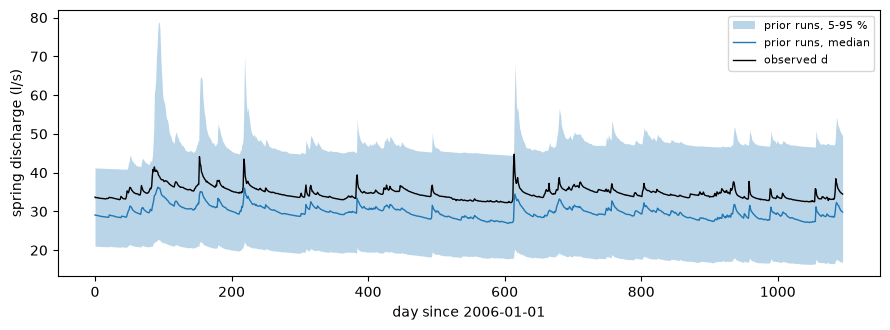

In [5]:
t = np.arange(len(d))
fig, ax = plt.subplots(figsize=(9, 3.4))
lo, med, hi = np.percentile(Qsim, [5, 50, 95], axis=0)
ax.fill_between(t, lo, hi, color='C0', alpha=0.3, lw=0, label='prior runs, 5-95 %')
ax.plot(t, med, color='C0', lw=1, label='prior runs, median')
ax.plot(t, d, color='k', lw=1, label='observed d')
ax.set_xlabel('day since 2006-01-01'); ax.set_ylabel('spring discharge (l/s)')
ax.legend(loc='upper right', fontsize=8)
fig.tight_layout()
print(f'simulated daily values below the observation: {100*np.mean(Qsim < d):.1f} %; '
      f'days on which the median run is below the observation: {100*np.mean(med < d):.1f} %')
plt.close(fig)
fig

Observed discharge and the spread of the 1000 prior runs. Most simulated values (65.5 %) lie below the observations, and the median run is below them on every day, so the misfit is large over most of the prior (median $1.43 \times 10^4$).

## Estimate the subspace

The gradients are exact and cheap, so the gradient estimator is used: $\hat{\mathbf{C}} = \frac1N\sum_i \nabla f_d(\mathbf{x}_i)\nabla f_d(\mathbf{x}_i)^\top$ with $N = 1000$ (the paper's $N$; ≥ 10·m and ≥ 300), and 500 bootstrap replicates. The space is $U[-1, 1]^{21}$ on $\mathbf{x}$, so the gradients are passed as they are. Eigenvector signs are set to match the paper's Fig. 3a–d.

In [6]:
space = ac.Uniform(-np.ones(21), np.ones(21), names=list(lm.CAL_NAMES))
sub = ac.active_subspace(space=space, X=X, grads=G, nboot=500, bootstrap_vectors=4, rng=SEED, qoi='f_d')
# signs as in the paper's Fig. 3a-d: w1 positive on D_log_kis_12, w2 positive on log_kis_1,
# w3 negative and w4 positive on D_log_kis_23
R = np.zeros((21, 4)); R[11, 0] = 1; R[4, 1] = 1; R[18, 2] = -1; R[18, 3] = 1
sub = ac.orient(sub, by='reference', reference=R, columns=4)
lam = sub.eigenvalues
blo, bhi = np.percentile(sub.bootstrap_eigenvalues, [2.5, 97.5], axis=0)
print('chosen dimension (rule %s): n = %d' % (sub.dimension_rule, sub.n))
for k in range(8):
    print(f'lambda_{k + 1} = {lam[k]:.3e}   95% bootstrap [{blo[k]:.3e}, {bhi[k]:.3e}]   lambda_{k + 1}/lambda_{k + 2} = {lam[k]/lam[k + 1]:.2f}')

chosen dimension (rule evg): n = 2
lambda_1 = 1.410e+09   95% bootstrap [1.264e+09, 1.743e+09]   lambda_1/lambda_2 = 1.85
lambda_2 = 7.618e+08   95% bootstrap [5.302e+08, 9.248e+08]   lambda_2/lambda_3 = 6.73
lambda_3 = 1.131e+08   95% bootstrap [1.008e+08, 1.265e+08]   lambda_3/lambda_4 = 2.19
lambda_4 = 5.170e+07   95% bootstrap [4.648e+07, 6.208e+07]   lambda_4/lambda_5 = 1.18
lambda_5 = 4.375e+07   95% bootstrap [3.738e+07, 5.249e+07]   lambda_5/lambda_6 = 1.34
lambda_6 = 3.266e+07   95% bootstrap [2.868e+07, 3.689e+07]   lambda_6/lambda_7 = 1.10
lambda_7 = 2.972e+07   95% bootstrap [2.030e+07, 3.282e+07]   lambda_7/lambda_8 = 2.91
lambda_8 = 1.021e+07   95% bootstrap [7.095e+06, 1.389e+07]   lambda_8/lambda_9 = 1.50


/tmp/ipykernel_9721/764757014.py:2: AccuracyWarning: bootstrap eigenvector replicates are poorly aligned with the full-sample vectors (columns [3]); their components are ill-defined, e.g. near repeated eigenvalues [accuracy.unaligned_replicates]
  sub = ac.active_subspace(space=space, X=X, grads=G, nboot=500, bootstrap_vectors=4, rng=SEED, qoi='f_d')


## Results

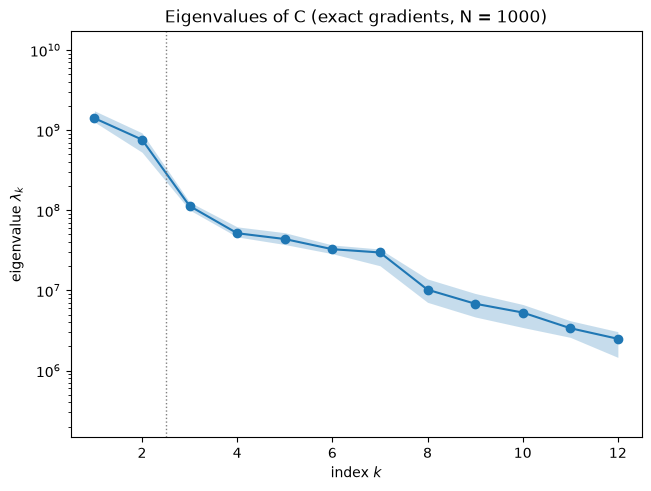

In [7]:
fig, ax = ac.plotting.plot_eigenvalues(sub, k_max=12)
ax.set_title('Eigenvalues of C (exact gradients, N = 1000)')
fig

The spectrum has its largest gap after $\lambda_2$: $\lambda_2/\lambda_3 = 6.73$, with non-overlapping 95 % bootstrap intervals ($\lambda_2 \in [5.302, 9.248]\times10^8$, $\lambda_3 \in [1.008, 1.265]\times10^8$). The first gap is smaller, $\lambda_1/\lambda_2 = 1.85$, and there is no clear gap after $\lambda_4$ ($\lambda_4/\lambda_5 = 1.18$). The eigenvalue-gap rule chooses $n = 2$.

mean bootstrap subspace distance, n = 1..6: [0.133 0.043 0.064 0.329 0.294 0.477]


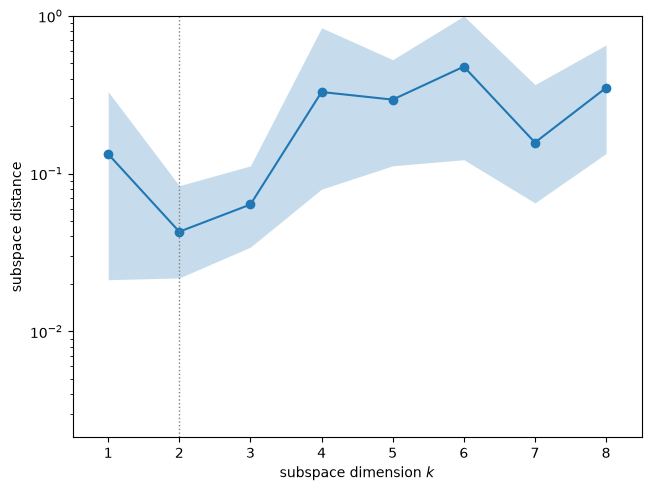

In [8]:
fig, ax = ac.plotting.plot_subspace_errors(sub, k_max=8)
dist = sub.bootstrap_distances.mean(axis=0)
print('mean bootstrap subspace distance, n = 1..6:', dist[:6].round(3))
fig

The bootstrap subspace distance is smallest for $n = 2$ (mean 0.043, against 0.133 for $n = 1$ and 0.329 for $n = 4$), so the two-dimensional subspace is estimated well even though its two basis vectors are less certain individually.

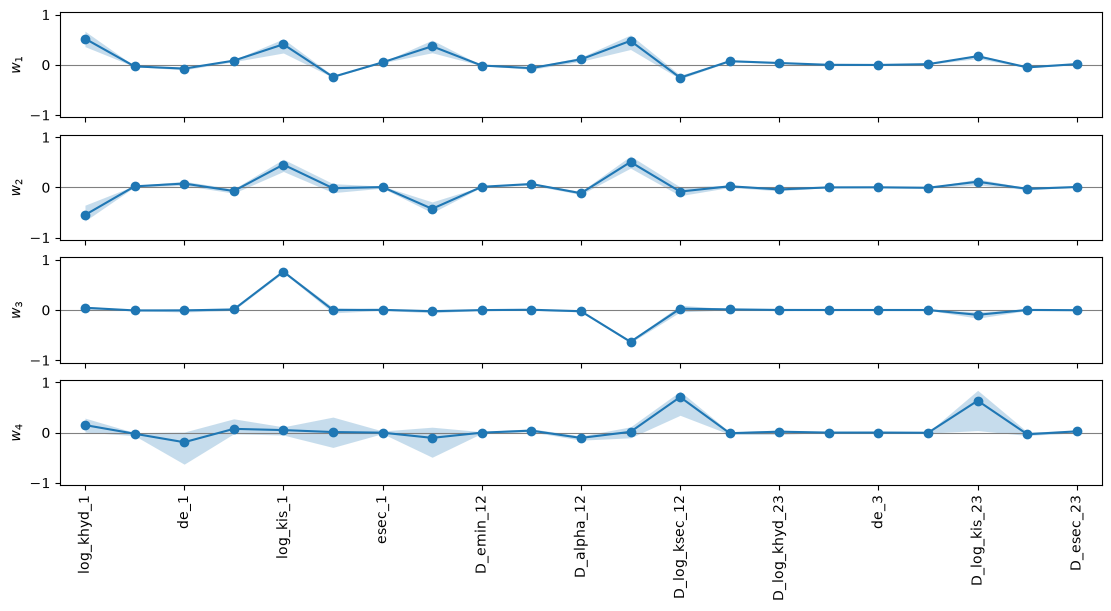

In [9]:
fig, axs = ac.plotting.plot_eigenvectors(sub, indices=[0, 1, 2, 3], interval='percentile', figsize=(11, 6))
for a in np.ravel(axs):
    a.set_xticks(range(1, 22, 2))
fig

In [10]:
W = sub.eigenvectors
for j in range(4):
    top = np.argsort(-np.abs(W[:, j]))[:4]
    print(f'w{j + 1}: ' + ', '.join(f'{lm.CAL_NAMES[i]} (No. {i + 1}) {W[i, j]:+.2f}' for i in top))

w1: log_khyd_1 (No. 1) +0.52, D_log_kis_12 (No. 12) +0.48, log_kis_1 (No. 5) +0.41, D_log_khyd_12 (No. 8) +0.37
w2: log_khyd_1 (No. 1) -0.55, D_log_kis_12 (No. 12) +0.51, log_kis_1 (No. 5) +0.45, D_log_khyd_12 (No. 8) -0.43
w3: log_kis_1 (No. 5) +0.76, D_log_kis_12 (No. 12) -0.63, D_log_kis_23 (No. 19) -0.10, log_khyd_1 (No. 1) +0.04
w4: D_log_ksec_12 (No. 13) +0.71, D_log_kis_23 (No. 19) +0.64, de_1 (No. 3) -0.19, log_khyd_1 (No. 1) +0.15


Eigenvectors in the coordinates $\mathbf{x}$ (bands: 95 % bootstrap). $\mathbf{w}_1$ and $\mathbf{w}_2$ are made of the same four inputs: the log quickflow coefficient of Hyd 1 (`log_khyd_1`, No. 1) and its Hyd 2 fraction (No. 8), and the log recharge coefficient of Hyd 1 (`log_kis_1`, No. 5) and its Hyd 2 fraction (No. 12). Their sum and difference separate the two groups, so the active subspace is close to span{quickflow direction of Hyd 1–2, recharge direction of Hyd 1–2}. $\mathbf{w}_3$ contrasts `log_kis_1` (+0.76) with `D_log_kis_12` (−0.63), and $\mathbf{w}_4$ is the secondary-spring coefficient of Hyd 2 (No. 13, +0.71) with the recharge fraction of Hyd 3 (No. 19, +0.64).

exact, largest five: No. 1 log_khyd_1 1.00, No. 12 D_log_kis_12 0.91, No. 5 log_kis_1 0.74, No. 8 D_log_khyd_12 0.56, No. 13 D_log_ksec_12 0.22
max/min sensitivity (exact): 7.87e+05
largest exact sensitivity outside Nos. 1, 5, 6, 8, 12, 13, 19: 0.052


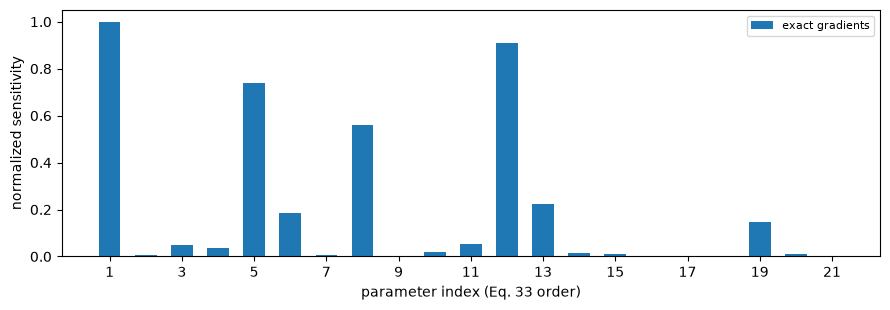

In [11]:
s_act = (W**2) @ lam                     # paper Eq. (17): s = (W o W) lambda, equal to diag(C)
s_norm = s_act/s_act.max()
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(np.arange(1, 22), s_norm, width=0.6, label='exact gradients')
ax.set_xticks(range(1, 22, 2)); ax.set_xlabel('parameter index (Eq. 33 order)'); ax.set_ylabel('normalized sensitivity')
ax.legend(fontsize=8); fig.tight_layout()
order = np.argsort(-s_norm)
print('exact, largest five:', ', '.join(f'No. {i + 1} {lm.CAL_NAMES[i]} {s_norm[i]:.2f}' for i in order[:5]))
print(f'max/min sensitivity (exact): {s_act.max()/s_act.min():.2e}')
rest = [i for i in range(21) if i + 1 not in (1, 5, 6, 8, 12, 13, 19)]
print(f'largest exact sensitivity outside Nos. 1, 5, 6, 8, 12, 13, 19: {s_norm[rest].max():.3f}')
plt.close(fig)
fig

Global sensitivities $s = (\mathbf{W}\circ\mathbf{W})\boldsymbol\lambda$ (paper Eq. 17), normalized to a maximum of 1. With exact gradients the order is `log_khyd_1` (1.00), `D_log_kis_12` (0.91), `log_kis_1` (0.74), `D_log_khyd_12` (0.56), `D_log_ksec_12` (0.22). The ratio of the largest to the smallest exact sensitivity is $7.87\times10^5$. The thresholds $e_{\min}$, $\triangle e$, $e_{\mathrm{sec}}$, the exponents $\alpha$ and every Hyd 3 parameter except No. 19 have sensitivities of at most 0.052. Sensitivities from finite differences are compared with the paper's Fig. 3e below.

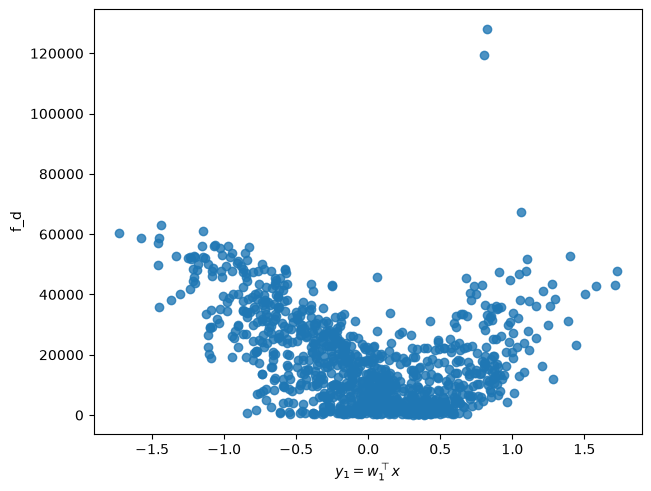

In [12]:
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=X, f=f, dims=1, qoi_label='f_d')
fig

Against one active variable the misfit is U-shaped with a wide spread (a quartic in $y_1$ explains less than half of the variance, below), consistent with the small first gap.

|y| < 0.5:  263 samples, median f_d = 8085
  y1 < -1:   49 samples, median f_d = 4.828e+04
   y1 > 1:   33 samples, median f_d = 3.377e+04


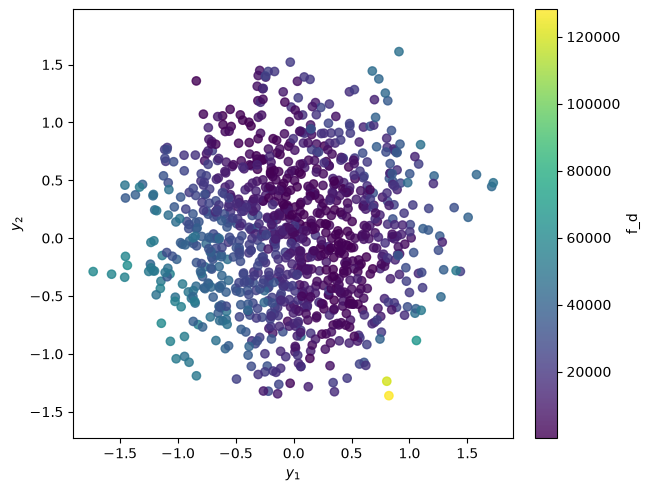

In [13]:
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=X, f=f, dims=2, qoi_label='f_d')
Y = (X @ sub.W[:, :2])
rad = np.linalg.norm(Y, axis=1)
for lab, msk in [('|y| < 0.5', rad < 0.5), ('y1 < -1', Y[:, 0] < -1), ('y1 > 1', Y[:, 0] > 1)]:
    print(f'{lab:>9}: {msk.sum():4d} samples, median f_d = {np.median(f[msk]):.4g}')
fig

Against two active variables the misfit is organized: the median misfit is 8085 for the 263 samples with $\lVert\mathbf{y}\rVert < 0.5$, against 4.828 × 10⁴ for $y_1 < -1$ (49 samples) and 3.377 × 10⁴ for $y_1 > 1$ (33 samples).

### Surrogate on the active variables

Quartic polynomials on 1, 2 and 4 active variables, fitted to the 1000 samples and tested on the 5000 independent validation samples. The paper fitted a quartic on its 4-D subspace and reported $r^2 \approx 0.77$.

In [14]:
fits = {}
for k in (1, 2, 4):
    sk = ac.active_subspace(space=space, X=X, grads=G, n=k)
    sur = ac.fit_surrogate(X=X, f=f, space=space, subspace=sk, kind='poly', degree=4)
    gv = sur.evaluate(Xv @ sk.W1)
    r2v = 1 - np.sum((fv - gv)**2)/np.sum((fv - fv.mean())**2)
    fits[k] = (sur, r2v)
    print(f'{k}-D quartic: LOO R^2 = {sur.loo_r_squared:.3f}, R^2 on the {len(fv)} validation samples = {r2v:.3f}')

1-D quartic: LOO R^2 = 0.470, R^2 on the 5000 validation samples = 0.472
2-D quartic: LOO R^2 = 0.777, R^2 on the 5000 validation samples = 0.787
4-D quartic: LOO R^2 = 0.843, R^2 on the 5000 validation samples = 0.851


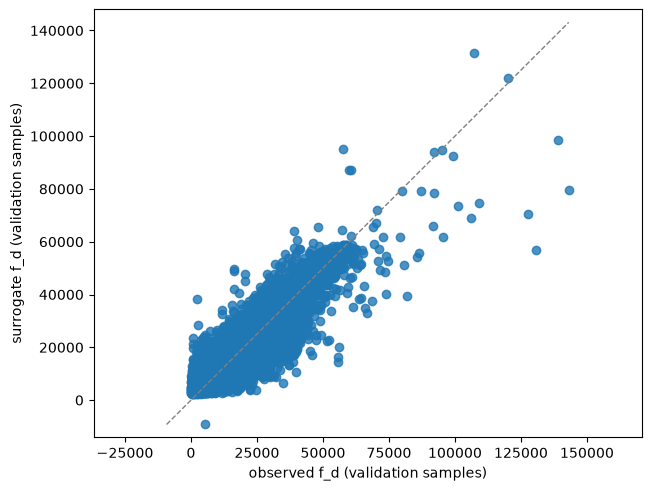

In [15]:
fig, ax = ac.plotting.plot_surrogate_fit(fits[2][0], X=Xv, f=fv, qoi_label='f_d (validation samples)')
fig

The 2-D quartic reaches LOO $R^2$ = 0.777 and validation $R^2$ = 0.787; four active variables raise these to 0.843 and 0.851, and one active variable gives only 0.470 and 0.472. The largest errors are at the few samples with very large misfits.

### Exact gradients, jumps and finite differences

The hysteresis switch makes quickflow jump from zero to $k_{\mathrm{hyd},i} a_i / l_{\mathrm{hyd},i}$ on the day $e_i$ reaches $e_{\max,i}$, so a parameter change that moves a switch by a day makes $f_d$ jump. The exact gradient in `gradients.csv` is the pathwise derivative, the derivative of the branch a sample is on, and $\hat{\mathbf{C}}$ estimates $\mathbb{E}[\nabla f_{\mathrm{pw}} \nabla f_{\mathrm{pw}}^\top]$, the part of the variation of $f_d$ that is differentiable. A central difference converges to it as $h \to 0$ whenever its stencil does not straddle a jump (next cell: at $h = 10^{-6}$ the relative error on the first 100 samples is at most $1.1\times10^{-5}$; DATA.md gives all 1000). A stencil that straddles a jump $J$ returns about $J/(2h)$ instead. The finite-difference matrix $\mathbf{C}_h$ therefore carries an extra diagonal term of order $\sum_j \rho_j\, \mathbb{E}[J^2]/(2h)$, with $\rho_j$ the density of jumps along $x_j$. This term grows like $1/h$, is sampled as rare outliers, and has no finite limit, so a $\mathbf{C}$ that includes the jumps does not exist. The jumps are small compared with $f_d$ (the largest one met in this data set is quantified below), so the pathwise $\mathbf{C}$ describes how the misfit varies, and it is the matrix this notebook reports. Strictly, the Poincaré-type error bound for the active-subspace approximation assumes a differentiable $f$, so it does not apply to $f_d$ as it stands.

In [16]:
import generate_data as gd   # numpy-only finite-difference helpers (fd_gradients, misfit_rounded)
Gs = gd.fd_gradients(X[:100], 1e-6)
rs = np.linalg.norm(Gs - G[:100], axis=1)/np.linalg.norm(G[:100], axis=1)
print(f'untruncated FD (h = 1e-6) vs exact, first 100 samples: median relative error {np.median(rs):.1e}, max {rs.max():.1e}')
rel = np.linalg.norm(Gfd - G, axis=1)/np.linalg.norm(G, axis=1)
print(f'untruncated FD (h = 1e-4) vs exact, relative error per sample: median {np.median(rel):.1e}, '
      f'max {rel.max():.1e} (row {np.argmax(rel)}); samples above 0.1: {int(np.sum(rel > 0.1))}')
r, j = 338, 11
jump = (Gfd[r, j] - G[r, j])*2e-4
print(f'row {r}: f_d = {f[r]:.4g}; df_d/dx_12 exact {G[r, j]:.4g}, FD {Gfd[r, j]:.4g}; '
      f'implied jump (FD - exact)*2h = {jump:.4g}, {100*abs(jump)/f[r]:.2f} % of f_d')
C_fd = Gfd.T @ Gfd/len(Gfd)
print(f'share of trace(C_FD) from row {r}: {np.sum(Gfd[r]**2)/len(Gfd)/np.trace(C_fd):.2f}')
keep = np.arange(len(Gfd)) != r
lam_fd = np.linalg.eigvalsh(C_fd)[::-1]
lam_k = np.linalg.eigvalsh(Gfd[keep].T @ Gfd[keep]/keep.sum())[::-1]
print('exact eigenvalues 1-3:                ', lam[:3])
print('FD eigenvalues 1-3, all 1000 samples: ', lam_fd[:3])
print('FD eigenvalues 1-3 without row 338:   ', lam_k[:3],
      f'; max relative difference from exact {np.max(np.abs(lam_k[:3]/lam[:3] - 1)):.4f}')

untruncated FD (h = 1e-6) vs exact, first 100 samples: median relative error 9.6e-09, max 1.1e-05
untruncated FD (h = 1e-4) vs exact, relative error per sample: median 8.3e-07, max 2.9e+01 (row 338); samples above 0.1: 13
row 338: f_d = 3.232e+04; df_d/dx_12 exact -5181, FD -6.925e+05; implied jump (FD - exact)*2h = -137.5, 0.43 % of f_d
share of trace(C_FD) from row 338: 0.27
exact eigenvalues 1-3:                 [1.4097e+09 7.6177e+08 1.1313e+08]
FD eigenvalues 1-3, all 1000 samples:  [2.0160e+09 1.0279e+09 1.2486e+08]
FD eigenvalues 1-3 without row 338:    [1.4146e+09 7.6507e+08 1.1378e+08] ; max relative difference from exact 0.0057


Untruncated finite differences at $h = 10^{-4}$ agree with the exact gradients for almost every sample (median relative error $8.3\times10^{-7}$; 13 samples have an error above 0.1). The largest error is at row 338, whose stencil in $x_{12}$ straddles a jump of $-137.5$ in $f_d$ (0.43 % of its $f_d$). This one sample carries 27 % of the trace of the FD matrix and raises its $\lambda_1$ from $1.410\times10^9$ to $2.016\times10^9$; without it the FD eigenvalues $\lambda_1$–$\lambda_3$ agree with the exact ones to within 0.6 % (largest relative difference 0.0057). Straddling a jump at this step is therefore a rare, one-sample effect, and it does not account for the paper's spectrum.

### Reproducibility note: parameter rounding in the authors' interface (a hypothesis)

The paper's spectrum (Fig. 2: $\lambda_1 \approx 1.2\times10^{10}$, gaps after $\lambda_1$ and $\lambda_4$; Fig. 3: $\mathbf{w}_1$ led by No. 12) differs from the one above. The paper gives no finite-difference step, and its 2019 code (Bitbucket) could not be reached from here. The closest available code is the authors' HydroShare resource for the follow-up study (Bittner et al., 2020/2021), which shares three authors and the LuKARS R script but uses a wavelet QoI. Its Python interface writes the physical parameters on the `Rscript` command line with the format `%f`, i.e. rounded to 6 decimals (`as_dwt/examples/as_wavelets/model.py`, line 35, abridged; `main_exe.R` reads them back with `as.numeric`, line 3):

```python
subprocess.run('Rscript.exe %s %s %f %f %f ... %f' %
               (env.scen_exe, self.id, self.k_e_2_num, self.e_min_2, ..., self.e_sec_4), shell=True, ...)
```

The $k_{\mathrm{is}}$ are the smallest parameters (down to $2.5\times10^{-4}$ for Hyd 3). A step $h$ in $\mathbf{x}$ moves them by $h\,\partial p/\partial x$, often less than one unit in the sixth decimal, so the difference quotient is either 0 or a one-digit change of the parameter divided by $2h$. If the 2019 pipeline passed parameters the same way, this quantization noise would inflate exactly the $k_{\mathrm{is}}$ directions, Nos. 5, 12 and 19. The cells below test that hypothesis with `generate_data.fd_gradients(..., rounded=True)`, which rounds the physical parameters as `'%f'` does before every run. (The same file uses $h = 10^{-4}$, line 75, and computes $(G(x-h) - G(x+h))/(2h)$, line 87, a sign flip that does not change $\mathbf{C}$.)

In [17]:
# Rounded finite differences: one check against the shipped files, and the effect of the step (first 100 samples)
t1 = time.time()
_, Jx = lm.to_physical(X, jac=True)  # dp/dx, shape (1000, 21, 21)
for j in (4, 11, 18):
    print(f'No. {j + 1} ({lm.NAMES[j]}): samples whose step moves the parameter by less than 1e-6: '
          f'h = 1e-4: {100*np.mean(np.abs(Jx[:, j, j])*1e-4 < 1e-6):.0f} %, h = 1e-5: {100*np.mean(np.abs(Jx[:, j, j])*1e-5 < 1e-6):.0f} %')
live = {h: gd.fd_gradients(X[:100], h, rounded=True) for h in (1e-4, 1e-5, 1e-6)}
print('rows 0-99 recomputed (h = 1e-5) vs gradients_fd_rounded.csv: max abs difference', np.abs(live[1e-5] - Gr75[:100]).max())
print('rows 0-19 recomputed with the 70 mm bound vs gradients_fd_rounded_lb70.csv: max abs difference',
      np.abs(gd.fd_gradients(X[:20], 1e-5, rounded=True, emin3_lb=70.0) - Gr70[:20]).max())
print(f'first 100 samples, exact gradients: lambda_1 = {np.linalg.eigvalsh(G[:100].T @ G[:100]/100)[-1]:.3e}')
for h, Gh in live.items():
    rn = np.sum(Gh**2, axis=1)
    print(f'first 100 samples, rounded FD, h = {h:g}: lambda_1 = {np.linalg.eigvalsh(Gh.T @ Gh/100)[-1]:.3e}, '
          f'largest single-sample share of trace(C) {rn.max()/rn.sum():.2f}')
print(f'{time.time() - t1:.0f} s')

No. 5 (kis_1): samples whose step moves the parameter by less than 1e-6: h = 1e-4: 16 %, h = 1e-5: 72 %
No. 12 (kis_2): samples whose step moves the parameter by less than 1e-6: h = 1e-4: 68 %, h = 1e-5: 97 %
No. 19 (kis_3): samples whose step moves the parameter by less than 1e-6: h = 1e-4: 94 %, h = 1e-5: 100 %


rows 0-99 recomputed (h = 1e-5) vs gradients_fd_rounded.csv: max abs difference 0.0


rows 0-19 recomputed with the 70 mm bound vs gradients_fd_rounded_lb70.csv: max abs difference 0.0
first 100 samples, exact gradients: lambda_1 = 1.458e+09
first 100 samples, rounded FD, h = 0.0001: lambda_1 = 1.517e+09, largest single-sample share of trace(C) 0.15
first 100 samples, rounded FD, h = 1e-05: lambda_1 = 7.397e+09, largest single-sample share of trace(C) 0.54
first 100 samples, rounded FD, h = 1e-06: lambda_1 = 9.586e+09, largest single-sample share of trace(C) 0.68
12 s


In [18]:
# The four gradient sets on all 1000 samples: spectra, bootstrap, eigenvectors, sensitivities
def spectrum(Gr, nboot=500):
    Cg = Gr.T @ Gr/len(Gr)
    l, Wg = np.linalg.eigh(Cg)
    l, Wg = l[::-1], Wg[:, ::-1]
    Wg = Wg*np.sign(Wg[np.argmax(np.abs(Wg), axis=0), range(21)])   # largest component positive
    rs = np.random.default_rng(SEED)
    l1 = [np.linalg.eigvalsh(Gr[i].T @ Gr[i]/len(i))[-1] for i in (rs.integers(0, len(Gr), len(Gr)) for _ in range(nboot))]
    rn = np.sum(Gr**2, axis=1)
    return dict(lam=l, W=Wg, boot=(min(l1), max(l1)), s=np.diag(Cg), top=rn.max()/rn.sum())

sets = {'exact': G, 'FD h = 1e-4, untruncated': Gfd,
        'FD h = 1e-5, %f-rounded, bound 75 mm': Gr75, 'FD h = 1e-5, %f-rounded, bound 70 mm': Gr70}
res = {k: spectrum(v) for k, v in sets.items()}
comp = lambda w, k: ', '.join(f'No. {i + 1} {w[i]:+.2f}' for i in np.argsort(-np.abs(w))[:k])
for k, q in res.items():
    l, s = q['lam'], q['s']
    print(k)
    print('  lambda_1-6:', ' '.join(f'{v:.3e}' for v in l[:6]), '| lambda_k/lambda_k+1, k = 1-5:', (l[:5]/l[1:6]).round(2))
    print(f"  lambda_1 bootstrap min-max (500): {q['boot'][0]:.2e} to {q['boot'][1]:.2e}; "
          f"largest single-sample share of trace(C): {q['top']:.2f}")
    print('  w1:', comp(q['W'][:, 0], 3), '| w2:', comp(q['W'][:, 1], 2), '| w3:', comp(q['W'][:, 2], 2), '| w4:', comp(q['W'][:, 3], 2))
    print('  sensitivity order:', ', '.join(f'No. {i + 1}' for i in np.argsort(-s)[:3]), f'| max/min {s.max()/s.min():.2e}')

exact
  lambda_1-6: 1.410e+09 7.618e+08 1.131e+08 5.170e+07 4.375e+07 3.266e+07 | lambda_k/lambda_k+1, k = 1-5: [1.85 6.73 2.19 1.18 1.34]
  lambda_1 bootstrap min-max (500): 1.22e+09 to 1.99e+09; largest single-sample share of trace(C): 0.06
  w1: No. 1 +0.52, No. 12 +0.48, No. 5 +0.41 | w2: No. 1 +0.55, No. 12 -0.51 | w3: No. 5 +0.76, No. 12 -0.63 | w4: No. 13 +0.71, No. 19 +0.64
  sensitivity order: No. 1, No. 12, No. 5 | max/min 7.87e+05
FD h = 1e-4, untruncated
  lambda_1-6: 2.016e+09 1.028e+09 1.249e+08 9.221e+07 5.132e+07 4.469e+07 | lambda_k/lambda_k+1, k = 1-5: [1.96 8.23 1.35 1.8  1.15]
  lambda_1 bootstrap min-max (500): 1.23e+09 to 5.60e+09; largest single-sample share of trace(C): 0.27
  w1: No. 12 +0.69, No. 5 +0.63, No. 1 +0.20 | w2: No. 1 +0.72, No. 8 +0.53 | w3: No. 5 +0.67, No. 12 -0.48 | w4: No. 13 +0.55, No. 12 +0.50
  sensitivity order: No. 12, No. 5, No. 1 | max/min 1.32e+06
FD h = 1e-5, %f-rounded, bound 75 mm
  lambda_1-6: 7.269e+09 1.910e+09 1.460e+09 6.476e+08

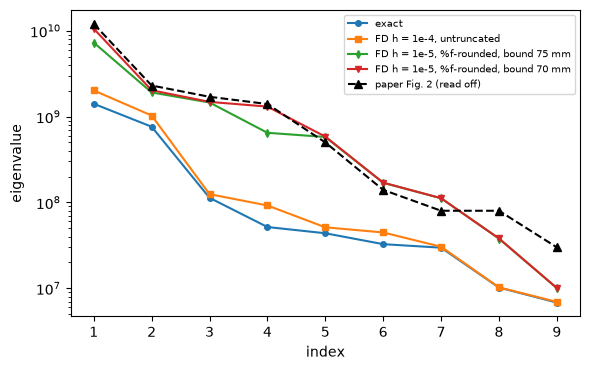

In [19]:
fig, ax = plt.subplots(figsize=(6, 3.8))
k = np.arange(1, 10)
for (lab, q), mk in zip(res.items(), 'osdv'):
    ax.semilogy(k, q['lam'][:9], mk + '-', ms=4, label=lab)
paper = [1.2e10, 2.3e9, 1.7e9, 1.4e9, 5e8, 1.4e8, 8e7, 8e7, 3e7]   # read off the paper's Fig. 2 (approximate)
ax.semilogy(k, paper, 'k^--', label='paper Fig. 2 (read off)')
ax.set_xlabel('index'); ax.set_ylabel('eigenvalue'); ax.legend(fontsize=7); fig.tight_layout()
plt.close(fig)
fig

Eigenvalues of the four gradient sets, with the paper's Fig. 2 values read off the figure (approximate; the paper prints no eigenvalues).

**Result of the test.** Rounding the parameters as the authors' interface does and taking central differences with $h = 10^{-5}$ largely reproduces the paper's Fig. 2 and Figs. 3a and 3e. With the 70 mm bound of the authors' settings file: $\lambda_1 = 1.055\times10^{10}$ (paper ≈ $1.2\times10^{10}$), gaps after $\lambda_1$ ($\lambda_1/\lambda_2 = 5.21$; paper ≈ 5) and after $\lambda_4$ ($\lambda_4/\lambda_5 = 2.24$; paper ≈ 2.8), a bootstrap range of $\lambda_1$ from $3.67\times10^9$ to $2.59\times10^{10}$ (paper ≈ $3.5\times10^9$ to $3.5\times10^{10}$), $\mathbf{w}_1$ led by Nos. 12, 5 and 19, the sensitivity order 12, 5, 19 of Fig. 3e, and a max/min sensitivity ratio of $7.03\times10^6$ (paper $3.6\times10^6$). With Table 1's 75 mm bound the pattern is the same but weaker: $\lambda_1 = 7.269\times10^9$, $\lambda_1/\lambda_2 = 3.8$, $\lambda_4/\lambda_5 = 2.25$, $\mathbf{w}_1$ led by Nos. 12 (+0.79) and 5 (+0.60), and sensitivities ordered 12, 5, 13. Neither version reproduces the paper's $\mathbf{w}_2$–$\mathbf{w}_4$ in detail.

The rounded spectra carry the marks of noise, not of model structure. $\lambda_1$ is $7.269\times10^9$ with one bound and $1.055\times10^{10}$ with the other, although $e_{\min,3}$ (No. 16) has an exact sensitivity of at most 0.052. On the first 100 samples, $\lambda_1$ of the rounded differences is $1.517\times10^9$, $7.397\times10^9$ and $9.586\times10^9$ for $h = 10^{-4}, 10^{-5}, 10^{-6}$ (exact: $1.458\times10^9$), and a single sample carries 0.15, 0.54 and 0.68 of the trace. On all 1000 samples the largest single sample carries 0.25 of the trace with the 70 mm bound and 0.09 with 75 mm, against 0.06 for the exact gradients. And the leading rounded eigenvectors are made of the $k_{\mathrm{is}}$ inputs (Nos. 12, 5, 19), the smallest parameters, for which 72–100 % of the $h = 10^{-5}$ steps move the parameter by less than one unit in the sixth decimal, while the exact $\mathbf{w}_1$ gives comparable weight to $k_{\mathrm{hyd},1}$ (No. 1).

**Conclusion, stated with care.** The paper's spectrum is *likely* an artifact of approximating gradients by finite differences through 6-decimal parameter rounding. This is a hypothesis consistent with the evidence, not a confirmed finding: the paper does not state its step, the code version behind its Fig. 2 could not be checked, and the authors' 2020 step ($h = 10^{-4}$) with rounding does not give $\lambda_1 \approx 10^{10}$ (first 100 samples above: $1.517\times10^9$; DATA.md has a 300-sample check). It is a note on reproducibility of the gradient approximation; the model, prior, data window and misfit agree with the paper.

## Comparison with the paper

| quantity | paper | notebook |
|---|---|---|
| model, data, prior | LuKARS, Kerschbaum 2006–2008, $\mathbf{x}\sim U[-1,1]^{21}$ (Eq. 33), 5 % noise | same; numpy port of the authors' R script (agrees to $3\times10^{-16}$), Table 1 bounds |
| gradient samples | $N$ = 1000, central finite differences (step not stated) | $N$ = 1000, exact (pathwise); for comparison, central FD untruncated ($h = 10^{-4}$) and through 6-decimal rounding ($h = 10^{-5}$) |
| $\lambda_1$ | ≈ $1.2\times10^{10}$ (read off Fig. 2) | $1.410\times10^9$ (exact); $2.016\times10^9$ (untruncated FD, from one sample); $7.269\times10^9$ / $1.055\times10^{10}$ (rounded FD, 75 / 70 mm bound) |
| gaps | after $\lambda_1$ and $\lambda_4$ (Fig. 2; $\lambda_1/\lambda_2 \approx 5$, $\lambda_4/\lambda_5 \approx 2.8$ read off) | exact: after $\lambda_2$ ($\lambda_1/\lambda_2$ = 1.85, $\lambda_2/\lambda_3$ = 6.73, $\lambda_4/\lambda_5$ = 1.18); rounded FD, 70 mm: $\lambda_1/\lambda_2$ = 5.21, $\lambda_4/\lambda_5$ = 2.24 |
| $\lambda_1$ bootstrap range | ≈ $3.5\times10^9$ to $3.5\times10^{10}$ (min–max band, Fig. 2) | exact: 95 % interval $1.264$–$1.743\times10^9$; rounded FD, 70 mm: min–max $3.67\times10^9$ to $2.59\times10^{10}$ |
| $\mathbf{w}_1$ | dominated by $\triangle k_{\mathrm{is},(1,2)}$ (No. 12, ≈ 0.95), then No. 5 (≈ 0.27) (Fig. 3a) | exact: No. 1 +0.52, No. 12 +0.48, No. 5 +0.41, No. 8 +0.37; rounded FD, 70 mm: No. 12 +0.74, No. 5 +0.62, No. 19 +0.27 |
| most sensitive parameters | No. 12, then 5 and 19 (Fig. 3e) | exact: No. 1, then 12 and 5; rounded FD, 70 mm: No. 12, then 5 and 19 |
| max/min sensitivity | $3.6\times10^6$ (Fig. 3 caption) | exact: $7.87\times10^5$; rounded FD, 70 mm: $7.03\times10^6$ |
| quartic surrogate | 4-D, $r^2 \approx 0.77$ | 4-D: LOO 0.843, validation 0.851; 2-D: LOO 0.777, validation 0.787 |

The model and the inputs agree with the paper; the spectrum does not. The headline of this notebook is the exact-gradient result: a two-dimensional active subspace ($\lambda_1/\lambda_2 = 1.85$, $\lambda_2/\lambda_3 = 6.73$) spanned by the quickflow ($k_{\mathrm{hyd}}$) and recharge ($k_{\mathrm{is}}$) coefficients of Hyd 1–2. It is the meaningful result because the gradients are exact derivatives of the model between its tiny jumps, checked against finite differences; because the estimate is stable (bootstrap subspace distance 0.043 for $n = 2$, no sample carrying more than 6 % of the trace); and because untruncated finite differences give the same matrix once the single jump-straddling sample is set aside. The 2-D quartic surrogate (validation $R^2$ = 0.787) confirms that two active variables carry most of the misfit's variation, on a par with the paper's 4-D $r^2 \approx 0.77$. The paper's larger spectrum, led by the $k_{\mathrm{is}}$ inputs, is largely reproduced by finite differences through the 6-decimal parameter rounding found in the authors' 2020 interface; we consider this the likely explanation, but the step and code version behind the 2019 figure are not stated, so the question is listed for the authors in DATA.md.

## Check

Re-running the model for five stored samples reproduces `outputs.csv` and `gradients.csv`.

In [20]:
# check: re-run the model for five stored samples
idx = [0, 1, 2, 500, 999]
f5, g5 = lm.misfit_and_grad(X[idx])
print('max rel. difference from outputs.csv:', f"{np.max(np.abs(f5 - f[idx])/f[idx]):.1e}",
      '; from gradients.csv (row norms):', f"{np.max(np.linalg.norm(g5 - G[idx], axis=1)/np.linalg.norm(G[idx], axis=1)):.1e}")
print(f'notebook run time so far: {time.time() - T0:.0f} s')

max rel. difference from outputs.csv: 0.0e+00 ; from gradients.csv (row norms): 3.1e-16
notebook run time so far: 21 s


## References

- M. Teixeira Parente, D. Bittner, S. A. Mattis, G. Chiogna, B. Wohlmuth, "Bayesian Calibration and Sensitivity Analysis for a Karst Aquifer Model Using Active Subspaces", *Water Resources Research* 55(8):7086–7107, 2019. [doi:10.1029/2019WR024739](https://doi.org/10.1029/2019WR024739)
- D. Bittner, T. Sheikhy Narany, B. Kohl, M. Disse, G. Chiogna, "Modeling the hydrological impact of land use change in a dolomite-dominated karst system", *Journal of Hydrology* 567:267–279, 2018. [doi:10.1016/j.jhydrol.2018.10.017](https://doi.org/10.1016/j.jhydrol.2018.10.017)
- D. Bittner, M. Engel, B. Wohlmuth, D. Labat, G. Chiogna, "Temporal Scale-Dependent Sensitivity Analysis for Hydrological Model Parameters Using the Discrete Wavelet Transform and Active Subspaces", *Water Resources Research* 57(10):e2020WR028511, 2021. [doi:10.1029/2020WR028511](https://doi.org/10.1029/2020WR028511)
- D. Bittner, M. Engel, B. Wohlmuth, D. Labat, G. Chiogna, "Discrete wavelet transform coupled with the active subspace method", HydroShare, 2020 (source of the LuKARS R code and the forcing data, CC BY 4.0). [doi:10.4211/hs.4901a0d654334c259f4ff9b49dc0a74e](https://doi.org/10.4211/hs.4901a0d654334c259f4ff9b49dc0a74e)
- P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM, 2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860)
- P. G. Constantine, P. Diaz, "Global sensitivity metrics from active subspaces", *Reliability Engineering & System Safety* 162:1–13, 2017. [doi:10.1016/j.ress.2017.01.013](https://doi.org/10.1016/j.ress.2017.01.013)

## Acknowledgments

From the paper: the work is a result of the UNMIX project, supported by the Deutsche Forschungsgemeinschaft (DFG) through the TUM International Graduate School for Science and Engineering (IGSSE), GSC 81; additional support for B. W., S. M. and M. T. P. from the DFG (Project WO 671/11-1); D. B. and G. C. acknowledge the Interreg Central Europe project PROLINE-CE (ERDF), and G. C. the Stiftungsfonds für Umweltökonomie und Nachhaltigkeit GmbH (SUN). The water works Waidhofen a.d. Ybbs provided the spatial and time-series data.